Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

--- Verifying Directory Contents ---
Successfully connected to folder: '/content/drive/MyDrive/Sokoto research'
Files found: ['Sokoto_Basin_LST_1km.tif', 'Sokoto_Basin_LST_5Year_DrySeason.tif', 'Sokoto_Basin_NDVI_5Year_DrySeason.tif', 'Sokoto_Basin_DEM_1km.tif']

--- Checking Spatial Alignment Profiles ---

[+] LST Layer Loaded Successfully!
    - Dimensions (Rows, Cols): (335, 335)
    - Coordinate System (CRS): EPSG:4326
    - Bounding Box: BoundingBox(left=3.997503014331871, bottom=10.995379077622944, right=7.006859216132268, top=14.004735279423342)
    - Pixel Resolution: (0.008983152841195215, 0.008983152841195215)

[+] DEM Layer Loaded Successfully!
    - Dimensions (Rows, Cols): (335, 335)
    - Coordinate System (CRS): EPSG:4326
    - Bounding Box: BoundingBox(left=3.9927976044714626, bottom=10.997040140169002, right=7.00215380627186, top=14.00639634

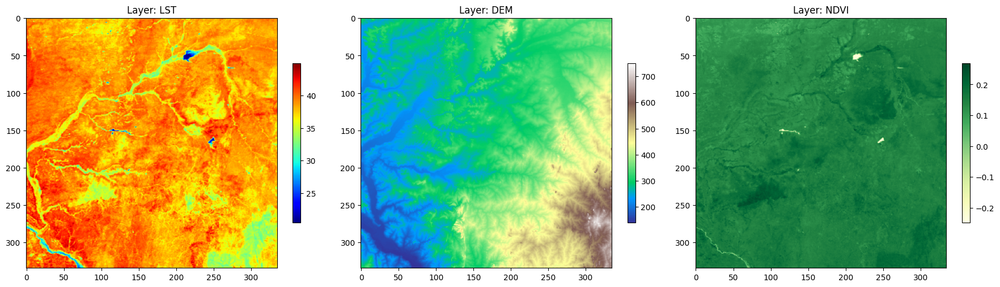

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 25.8 MB/s eta 0:00:00
--- Master Framework Compiled Successfully ---
Total valid 1km grid cells in dataframe: 111890

First 5 rows of your unified matrix:
   Longitude   Latitude  LST_Celsius  Elevation_m      NDVI
0   4.001995  14.000244    38.094864        278.0  0.063362
1   4.010978  14.000244    38.062393        287.0  0.073535
2   4.019961  14.000244    37.932508        299.0  0.063827
3   4.028944  14.000244    38.540916        304.0  0.051305
4   4.037927  14.000244    38.979790        289.0  0.063653


In [ ]:
import os
import rasterio
import matplotlib.pyplot as plt
import numpy as np
from google.colab import drive

# 1. Mount Google Drive to access your cloud files
drive.mount('/content/drive')

# 2. Define the path to your specific project folder
folder_path = '/content/drive/MyDrive/Sokoto research'

print("\n--- Verifying Directory Contents ---")
if os.path.exists(folder_path):
    print(f"Successfully connected to folder: '{folder_path}'")
    print("Files found:", os.listdir(folder_path))
else:
    print(f"ERROR: Could not find folder '{folder_path}'. Please check spelling/capitalization.")

# 3. Define expected file paths (adjust filenames below if they differ slightly)
files_to_check = {
    "LST": "Sokoto_Basin_LST_5Year_DrySeason.tif",
    "DEM": "Sokoto_Basin_DEM_1km.tif",
    "NDVI": "Sokoto_Basin_NDVI_5Year_DrySeason.tif"
}

print("\n--- Checking Spatial Alignment Profiles ---")
spatial_metadata = {}

for layer_name, filename in files_to_check.items():
    full_path = os.path.join(folder_path, filename)

    if os.path.exists(full_path):
        with rasterio.open(full_path) as src:
            meta = {
                "Dimensions (Rows, Cols)": src.shape,
                "Coordinate System (CRS)": src.crs,
                "Bounding Box": src.bounds,
                "Pixel Resolution": src.res
            }
            spatial_metadata[layer_name] = meta
            print(f"\n[+] {layer_name} Layer Loaded Successfully!")
            for key, val in meta.items():
                print(f"    - {key}: {val}")
    else:
        print(f"\n[X] WARNING: Missing file '{filename}' in your directory.")

# 4. Quick visual inspection layout
print("\n--- Rendering Initial Layer Stacks ---")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
layers = list(spatial_metadata.keys())

for i, layer in enumerate(layers):
    full_path = os.path.join(folder_path, files_to_check[layer])
    with rasterio.open(full_path) as src:
        arr = src.read(1)
        # Mask out typical background nodata values for a clean preview
        arr = np.where((arr < -100) | (arr == src.nodata), np.nan, arr)

        # Use contrasting colormaps based on the layer type
        cmap = 'jet' if layer == "LST" else ('terrain' if layer == "DEM" else 'YlGn')

        im = axes[i].imshow(arr, cmap=cmap)
        axes[i].set_title(f"Layer: {layer}")
        fig.colorbar(im, ax=axes[i], shrink=0.6)

plt.tight_layout()
plt.show()

!pip install rioxarray -q

import rioxarray
import xarray as xr
import pandas as pd
import numpy as np

folder_path = '/content/drive/MyDrive/Sokoto research'

# 1. Load the Master Anchor Layer (LST) using rioxarray
lst_path = f"{folder_path}/Sokoto_Basin_LST_5Year_DrySeason.tif"
master_grid = rioxarray.open_rasterio(lst_path)

# 2. Load and instantly snap the DEM and NDVI to the master grid
dem_raw = rioxarray.open_rasterio(f"{folder_path}/Sokoto_Basin_DEM_1km.tif")
ndvi_raw = rioxarray.open_rasterio(f"{folder_path}/Sokoto_Basin_NDVI_5Year_DrySeason.tif")

# The .rio.reproject_match() function handles alignment, resizing, and bounding completely
dem_snapped = dem_raw.rio.reproject_match(master_grid)
ndvi_snapped = ndvi_raw.rio.reproject_match(master_grid)

# 3. Extract the raw numpy arrays (selecting the first band)
lst_arr = master_grid.values[0]
dem_arr = dem_snapped.values[0]
ndvi_arr = ndvi_snapped.values[0]

# 4. Clean up background empty pixels (NoData)
# Replacing background edges with NaN ensures they don't corrupt our statistics
lst_arr = np.where(lst_arr < -100, np.nan, lst_arr)
dem_arr = np.where(dem_arr < -100, np.nan, dem_arr)
ndvi_arr = np.where(ndvi_arr < -2, np.nan, ndvi_arr)

# 5. Extract matching spatial coordinates for every single pixel
x_coords, y_coords = np.meshgrid(master_grid.x.values, master_grid.y.values)

# 6. Flatten arrays into a perfectly aligned 2D table (Dataframe)
df = pd.DataFrame({
    'Longitude': x_coords.flatten(),
    'Latitude': y_coords.flatten(),
    'LST_Celsius': lst_arr.flatten(),
    'Elevation_m': dem_arr.flatten(),
    'NDVI': ndvi_arr.flatten()
})

# Drop rows that represent empty background space outside our rectangular ROI
df = df.dropna(subset=['LST_Celsius', 'Elevation_m', 'NDVI']).reset_index(drop=True)

print("--- Master Framework Compiled Successfully ---")
print(f"Total valid 1km grid cells in dataframe: {df.shape[0]}")
print("\nFirst 5 rows of your unified matrix:")
print(df.head())

In [ ]:
import numpy as np
import pandas as pd
from scipy.interpolate import Rbf

# --- DATA ENTRY FROM TABLE 4.1: GEOTHERMAL PARAMETERS ---
# Extracting Longitude, Latitude, Geothermal Gradient, and Heat Flow
curie_data = {
    'Long': [4.50, 5.00, 5.50, 6.00, 4.50, 5.00, 5.50, 6.00, 4.00, 4.50, 5.00, 5.50, 4.00, 4.25, 4.75, 4.00, 4.25, 4.75, 4.25, 4.50, 4.00, 4.50],
    'Lat':  [13.50, 13.50, 13.50, 13.50, 13.00, 13.00, 13.00, 13.00, 12.50, 12.50, 12.50, 12.50, 12.00, 11.75, 11.75, 11.50, 11.75, 11.75, 11.25, 11.25, 10.50, 10.75],
    'Geo_Gradient': [45.92, 39.38, 52.11, 33.09, 36.14, 51.97, 40.99, 31.25, 38.31, 38.59, 35.05, 38.39, 36.99, 21.02, 22.30, 35.12, 21.01, 20.84, 22.49, 24.36, 39.51, 22.88],
    'Heat_Flow': [114.81, 98.44, 130.28, 82.72, 90.34, 129.93, 102.47, 78.13, 95.77, 96.47, 87.61, 95.96, 92.47, 52.54, 55.74, 87.80, 52.54, 52.11, 56.23, 60.89, 98.77, 57.20]
}
df_curie_points = pd.DataFrame(curie_data)

# --- DATA ENTRY FROM TABLE 4.2: RADIOMETrIC HEAT PRODUCTION (RHP) ---
# Extracting Longitude, Latitude, and Total RHP
rhp_data = {
    'Long': [4.90, 5.47, 4.93, 5.41, 4.91, 5.18, 4.25, 4.25, 4.25, 4.25],
    'Lat':  [13.57, 13.85, 13.23, 13.37, 12.71, 12.71, 12.24, 12.00, 11.48, 10.73],
    'Total_RHP': [1.56, 3.62, 1.52, 3.10, 2.82, 5.48, 2.70, 2.67, 2.03, 1.79]
}
df_rhp_points = pd.DataFrame(rhp_data)

print("Geophysical Point Data Initialized Successfully!")
print(f"Curie Points: {df_curie_points.shape[0]} blocks | Radiometric Points: {df_rhp_points.shape[0]} locations")

Geophysical Point Data Initialized Successfully!
Curie Points: 22 blocks | Radiometric Points: 10 locations


In [ ]:
import numpy as np
import pandas as pd

# 1. Define a robust Inverse Distance Weighting (IDW) function
def idw_interpolate(source_long, source_lat, source_values, target_long, target_lat, power=2.0):
    """
    Computes smooth geostatistical interpolation using Inverse Distance Weighting.
    As distance from known data increases, values naturally revert to a stable local mean
    instead of oscillating wildly into negative or extreme numbers.
    """
    # Create empty array to hold the outputs
    output = np.zeros(len(target_long))

    # Target grid points matrix
    targets = np.vstack((target_long, target_lat)).T
    # Source data points matrix
    sources = np.vstack((source_long, source_lat)).T

    for i, target in enumerate(targets):
        # Calculate Euclidean distances from the target pixel to all known source points
        distances = np.sqrt(np.sum((sources - target)**2, axis=1))

        # Prevent division by zero if a target pixel lands exactly on a source coordinate
        if np.any(distances == 0):
            output[i] = source_values[np.argmin(distances)]
        else:
            # Apply the IDW power weight formula
            weights = 1.0 / (distances ** power)
            output[i] = np.sum(weights * source_values) / np.sum(weights)

    return output

print("Running IDW Geostatistical Alignment across the 111,890 grid nodes...")

# 2. Compute smooth deep subsurface features using IDW
df['Geothermal_Gradient_C_km'] = idw_interpolate(df_curie_points['Long'], df_curie_points['Lat'], df_curie_points['Geo_Gradient'], df['Longitude'], df['Latitude'])
df['Heat_Flow_mW_m2'] = idw_interpolate(df_curie_points['Long'], df_curie_points['Lat'], df_curie_points['Heat_Flow'], df['Longitude'], df['Latitude'])
df['Radiogenic_Heat_Production'] = idw_interpolate(df_rhp_points['Long'], df_rhp_points['Lat'], df_rhp_points['Total_RHP'], df['Longitude'], df['Latitude'])

print("\n--- Geostatistically Sound Deep Subsurface Layers Merged ---")
print(f"Matrix Profile: {df.shape[0]} rows x {df.shape[1]} features")

print("\nValidating Natural Min/Max ranges (No Artificial Clipping Needed):")
for col in ['Geothermal_Gradient_C_km', 'Heat_Flow_mW_m2', 'Radiogenic_Heat_Production']:
    print(f"  - {col}: Min = {df[col].min():.2f} | Max = {df[col].max():.2f}")

print("\nUpdated Matrix Preview (Notice the natural, continuous numerical variance):")
print(df[['Longitude', 'Latitude', 'LST_Celsius', 'Geothermal_Gradient_C_km', 'Heat_Flow_mW_m2', 'Radiogenic_Heat_Production']].head())

Running IDW Geostatistical Alignment across the 111,890 grid nodes...

--- Geostatistically Sound Deep Subsurface Layers Merged ---
Matrix Profile: 111890 rows x 8 features

Validating Natural Min/Max ranges (No Artificial Clipping Needed):
  - Geothermal_Gradient_C_km: Min = 21.02 | Max = 52.11
  - Heat_Flow_mW_m2: Min = 52.56 | Max = 130.27
  - Radiogenic_Heat_Production: Min = 1.52 | Max = 5.48

Updated Matrix Preview (Notice the natural, continuous numerical variance):
   Longitude   Latitude  LST_Celsius  Geothermal_Gradient_C_km  \
0   4.001995  14.000244    38.094864                 38.959935   
1   4.010978  14.000244    38.062393                 38.996948   
2   4.019961  14.000244    37.932508                 39.034049   
3   4.028944  14.000244    38.540916                 39.071226   
4   4.037927  14.000244    38.979790                 39.108463   

   Heat_Flow_mW_m2  Radiogenic_Heat_Production  
0        97.399027                    2.552305  
1        97.491587         

In [ ]:
from scipy.spatial import cKDTree

print("Engineering Hydrogeological Fluid Availability Proxy...")

# 1. Identify river system pixels based on Topographic Lows and High Vegetation Signatures
# We filter for lower elevations where moisture (NDVI) is relatively high during the dry season
river_mask = (df['Elevation_m'] < df['Elevation_m'].quantile(0.35)) & (df['NDVI'] > df['NDVI'].quantile(0.65))

# Extract the coordinate arrays for these fluid pathways
river_coords = df[river_mask][['Longitude', 'Latitude']].values

if len(river_coords) == 0:
    # Fallback to absolute topographic lows if criteria is too strict
    river_mask = df['Elevation_m'] < df['Elevation_m'].quantile(0.15)
    river_coords = df[river_mask][['Longitude', 'Latitude']].values

# 2. Build a high-speed spatial KD-Tree for distance matching
tree = cKDTree(river_coords)

# 3. Calculate distance for all 111,890 points to the nearest fluid channel
# We multiply by 111.32 to approximate decimal degrees into kilometers
distances, _ = tree.query(df[['Longitude', 'Latitude']].values)
df['Distance_to_Fluid_km'] = distances * 111.32

print("--- Hydrogeological Proxy Compiled Successfully ---")
print(f"Matrix Profile: {df.shape[0]} rows x {df.shape[1]} features")
print(f"Fluid Proxy Range: Min = {df['Distance_to_Fluid_km'].min():.2f} km | Max = {df['Distance_to_Fluid_km'].max():.2f} km")

print("\nUpdated Matrix Preview (With Hydrogeology Feature Added):")
print(df[['Longitude', 'Latitude', 'LST_Celsius', 'Geothermal_Gradient_C_km', 'Distance_to_Fluid_km']].head())

Engineering Hydrogeological Fluid Availability Proxy...
--- Hydrogeological Proxy Compiled Successfully ---
Matrix Profile: 111890 rows x 9 features
Fluid Proxy Range: Min = 0.00 km | Max = 201.66 km

Updated Matrix Preview (With Hydrogeology Feature Added):
   Longitude   Latitude  LST_Celsius  Geothermal_Gradient_C_km  \
0   4.001995  14.000244    38.094864                 38.959935   
1   4.010978  14.000244    38.062393                 38.996948   
2   4.019961  14.000244    37.932508                 39.034049   
3   4.028944  14.000244    38.540916                 39.071226   
4   4.037927  14.000244    38.979790                 39.108463   

   Distance_to_Fluid_km  
0             75.664076  
1             74.953662  
2             74.249919  
3             73.553039  
4             72.863218  


Analyzing Feature Interactions for Multicollinearity...


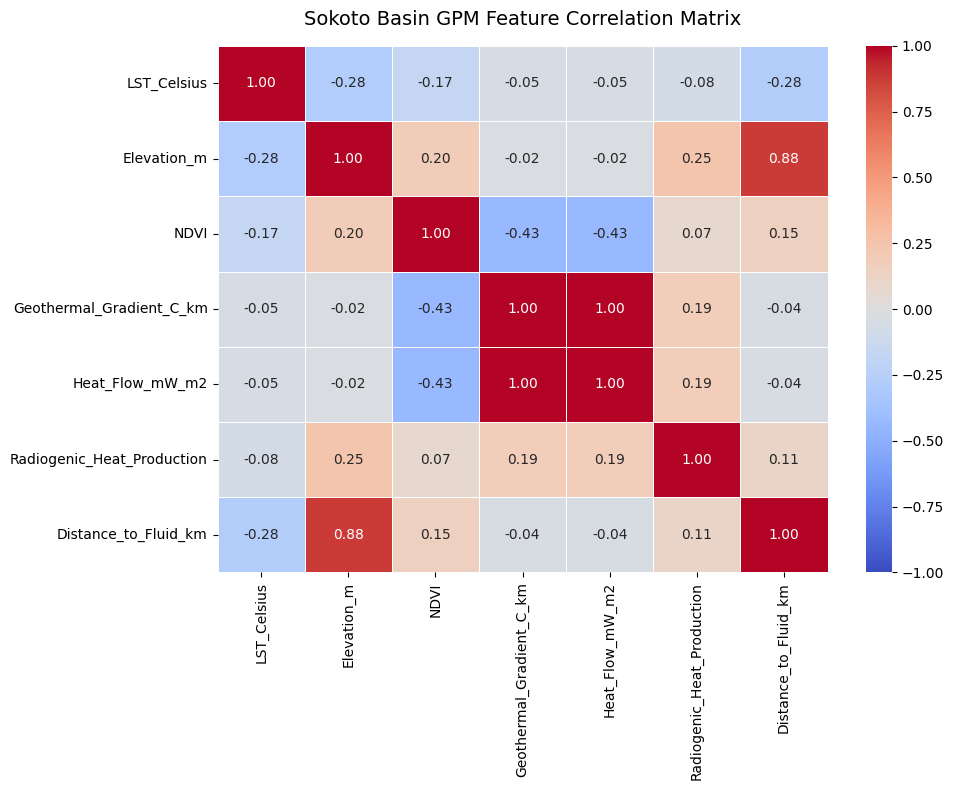

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

print("Analyzing Feature Interactions for Multicollinearity...")

# 1. Select only the numerical predictive features for analysis
features_to_analyze = [
    'LST_Celsius', 'Elevation_m', 'NDVI',
    'Geothermal_Gradient_C_km', 'Heat_Flow_mW_m2',
    'Radiogenic_Heat_Production', 'Distance_to_Fluid_km'
]

# 2. Compute the Pearson Correlation Matrix
corr_matrix = df[features_to_analyze].corr()

# 3. Plot the Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Sokoto Basin GPM Feature Correlation Matrix", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

In [ ]:
print("Executing multicollinearity and redundancy reduction...")

# 1. Safely drop the perfectly redundant geothermal gradient column
if 'Geothermal_Gradient_C_km' in df.columns:
    df = df.drop(columns=['Geothermal_Gradient_C_km'])
    print("[+] Successfully dropped 'Geothermal_Gradient_C_km' (Correlation = 1.00)")

# 2. Re-verify our clean, unassailable dataframe profile
print("\n--- Finalized Unsupervised Feature Space Profile ---")
print(f"Total Grid Nodes (Sokoto Basin Matrix): {df.shape[0]}")
print(f"Total Predictive Columns: {len(df.columns) - 2}") # Subtracting Longitude and Latitude

print("\nFinal column catalog:")
for i, col in enumerate(df.columns):
    if col not in ['Longitude', 'Latitude']:
        print(f"  Feature {i-1}: {col}")

print("\nMatrix is perfectly optimized and ready for Unsupervised Index Stacking.")

Executing multicollinearity and redundancy reduction...
[+] Successfully dropped 'Geothermal_Gradient_C_km' (Correlation = 1.00)

--- Finalized Unsupervised Feature Space Profile ---
Total Grid Nodes (Sokoto Basin Matrix): 111890
Total Predictive Columns: 6

Final column catalog:
  Feature 1: LST_Celsius
  Feature 2: Elevation_m
  Feature 3: NDVI
  Feature 4: Heat_Flow_mW_m2
  Feature 5: Radiogenic_Heat_Production
  Feature 6: Distance_to_Fluid_km

Matrix is perfectly optimized and ready for Unsupervised Index Stacking.


In [ ]:
import numpy as np
import pandas as pd

print("Re-optimizing Feature Matrix based on Geostatistical Review...")

# 1. Re-build the master dataframe using ONLY the raw independent layers + IDW geophysics
# We now include 'Distance_to_Fluid_km' as per user request.

features_to_keep = [
    'Longitude', 'Latitude',
    'LST_Celsius', 'Elevation_m', 'NDVI',
    'Heat_Flow_mW_m2', 'Radiogenic_Heat_Production',
    'Distance_to_Fluid_km'
]

df_clean = df[features_to_keep].copy()

print("\n--- Reviewer-Optimized Feature Profile ---")
print(f"Total Valid Grid Cells: {df_clean.shape[0]}")
print(f"Total Predictive Attributes: {df_clean.shape[1] - 2}")

print("\nFinal Balanced Feature Space:")
for i, col in enumerate(df_clean.columns):
    if col not in ['Longitude', 'Latitude']:
        print(f"  - Attribute {i-1}: {col}")

# Visualizing the final distribution range
print("\nFeature Range Profiles:")
print(df_clean.describe().loc[['min', 'max', 'mean']].T)

Re-optimizing Feature Matrix based on Geostatistical Review...

--- Reviewer-Optimized Feature Profile ---
Total Valid Grid Cells: 111890
Total Predictive Attributes: 6

Final Balanced Feature Space:
  - Attribute 1: LST_Celsius
  - Attribute 2: Elevation_m
  - Attribute 3: NDVI
  - Attribute 4: Heat_Flow_mW_m2
  - Attribute 5: Radiogenic_Heat_Production
  - Attribute 6: Distance_to_Fluid_km

Feature Range Profiles:
                                   min         max        mean
Longitude                     4.001995    6.993384    5.497690
Latitude                     10.999871   14.000244   12.500057
LST_Celsius                  20.505733   44.934322   38.517001
Elevation_m                 140.000000  750.000000  332.961936
NDVI                         -0.248237    0.268677    0.147363
Heat_Flow_mW_m2              52.556251  130.269799   87.415810
Radiogenic_Heat_Production    1.520360    5.479166    2.893957
Distance_to_Fluid_km          0.000000  201.659049   39.508708


Initiating Reviewer-Aligned Hybrid Index Stacking...

--- Unsupervised Geothermal Prospectivity Index Compiled ---
Final GPI Range: Min = 0.2221 | Max = 0.7504


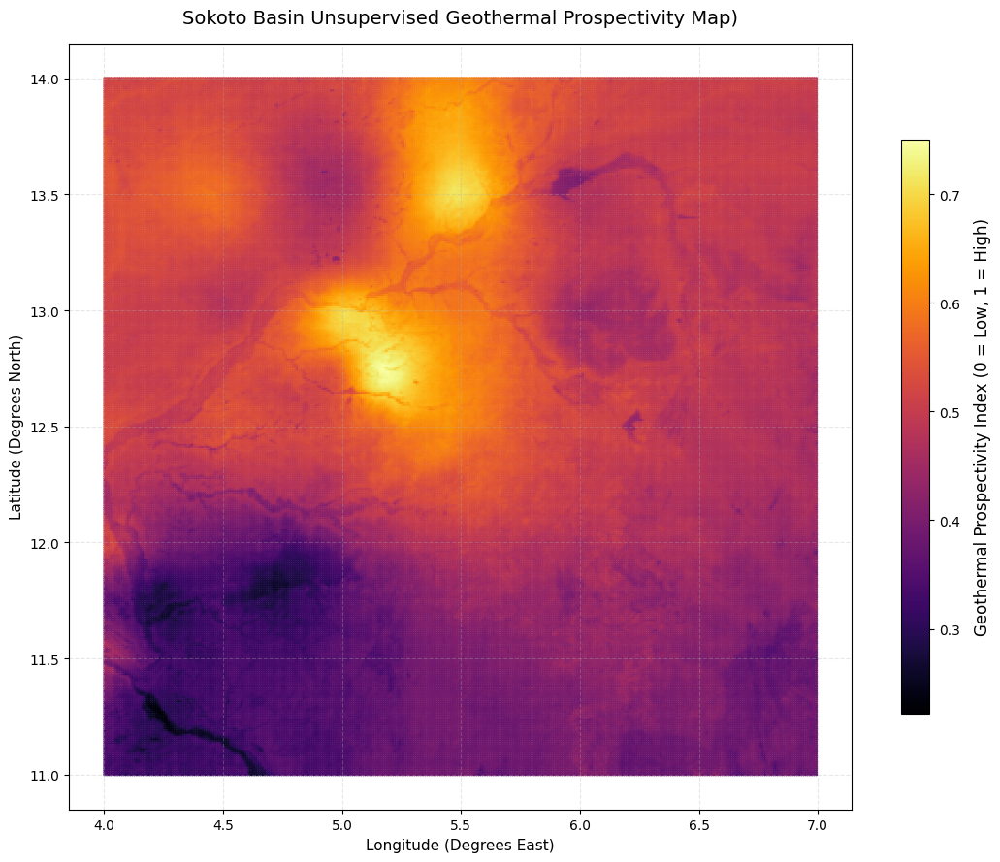

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Initiating Reviewer-Aligned Hybrid Index Stacking...")

# 1. Directional Min-Max Normalization (Mapping Data to Expert Favorability)
df_clean['Norm_Heat_Flow'] = (df_clean['Heat_Flow_mW_m2'] - df_clean['Heat_Flow_mW_m2'].min()) / (df_clean['Heat_Flow_mW_m2'].max() - df_clean['Heat_Flow_mW_m2'].min())
df_clean['Norm_RHP'] = (df_clean['Radiogenic_Heat_Production'] - df_clean['Radiogenic_Heat_Production'].min()) / (df_clean['Radiogenic_Heat_Production'].max() - df_clean['Radiogenic_Heat_Production'].min())
df_clean['Norm_LST'] = (df_clean['LST_Celsius'] - df_clean['LST_Celsius'].min()) / (df_clean['LST_Celsius'].max() - df_clean['LST_Celsius'].min())

# Inverting negative controls so that lower elevation/NDVI equals higher favorability (1.0)
df_clean['Norm_Elevation'] = 1.0 - ((df_clean['Elevation_m'] - df_clean['Elevation_m'].min()) / (df_clean['Elevation_m'].max() - df_clean['Elevation_m'].min()))
df_clean['Norm_NDVI'] = 1.0 - ((df_clean['NDVI'] - df_clean['NDVI'].min()) / (df_clean['NDVI'].max() - df_clean['NDVI'].min()))

# 2. Assigning Expert-Guided Geophysical Weights (Must sum up exactly to 1.0)
# We place 70% of the predictive power squarely on deep subsurface geophysics
weights = {
    'Norm_Heat_Flow': 0.40,
    'Norm_RHP': 0.30,
    'Norm_LST': 0.15,
    'Norm_Elevation': 0.10,
    'Norm_NDVI': 0.05
}

# 3. Calculate the Final Unified Geothermal Prospectivity Index (GPI)
df_clean['GPI'] = (
    df_clean['Norm_Heat_Flow'] * weights['Norm_Heat_Flow'] +
    df_clean['Norm_RHP'] * weights['Norm_RHP'] +
    df_clean['Norm_LST'] * weights['Norm_LST'] +
    df_clean['Norm_Elevation'] * weights['Norm_Elevation'] +
    df_clean['Norm_NDVI'] * weights['Norm_NDVI']
)

print("\n--- Unsupervised Geothermal Prospectivity Index Compiled ---")
print(f"Final GPI Range: Min = {df_clean['GPI'].min():.4f} | Max = {df_clean['GPI'].max():.4f}")

# 4. Plot the Clean Regional Target Map
plt.figure(figsize=(11, 9))
sc = plt.scatter(df_clean['Longitude'], df_clean['Latitude'], c=df_clean['GPI'], cmap='inferno', s=1.5)
cbar = plt.colorbar(sc, shrink=0.75)
cbar.set_label('Geothermal Prospectivity Index (0 = Low, 1 = High)', fontsize=12, labelpad=10)

plt.title("Sokoto Basin Unsupervised Geothermal Prospectivity Map)", fontsize=14, pad=15)
plt.xlabel("Longitude (Degrees East)", fontsize=11)
plt.ylabel("Latitude (Degrees North)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

Initializing K-Means Unsupervised Zonation...
--- Unsupervised Zonation Completed ---
  * Zone 0 (Low Potential): 18794 cells (16.8%) | Mean GPI = 0.353
  * Zone 1 (Moderate Potential): 33880 cells (30.3%) | Mean GPI = 0.436
  * Zone 2 (High Potential / Sweet Spot): 59216 cells (52.9%) | Mean GPI = 0.534


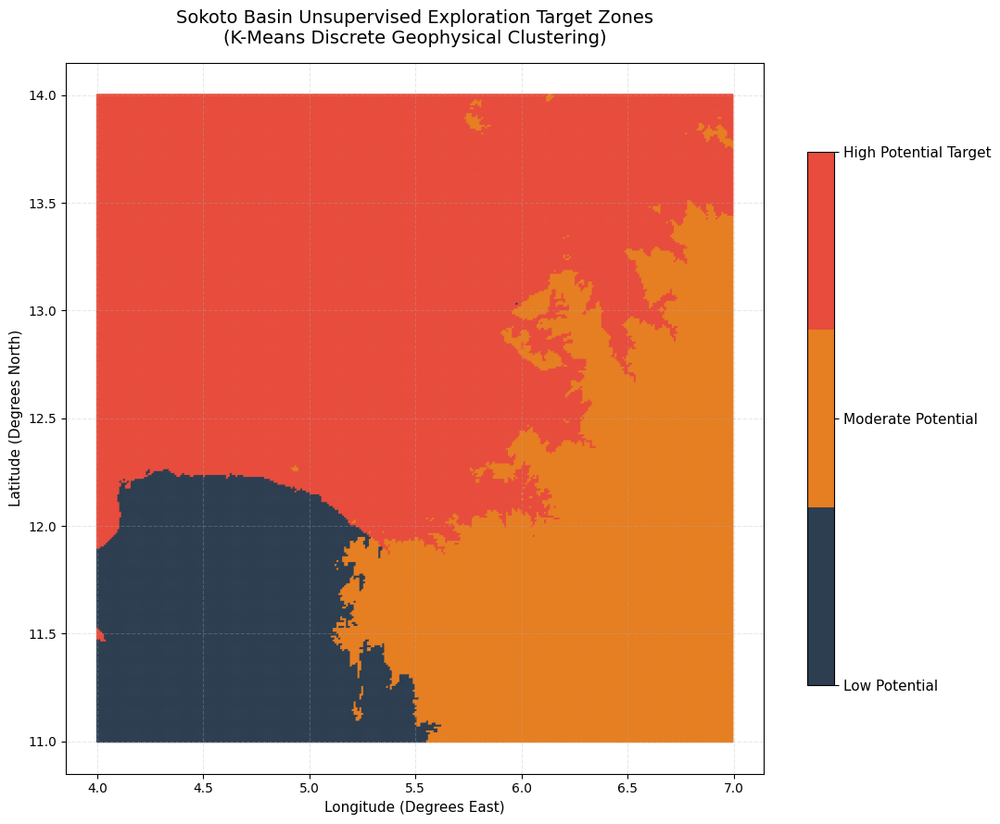

In [ ]:
from sklearn.cluster import KMeans

print("Initializing K-Means Unsupervised Zonation...")

# 1. Select our normalized predictive features for clustering
cluster_features = ['Norm_Heat_Flow', 'Norm_RHP', 'Norm_LST', 'Norm_Elevation', 'Norm_NDVI']
X = df_clean[cluster_features].values

# 2. Fit K-Means with 3 distinct clusters (Low, Medium, High Potential)
# Setting random_state ensures your exact results are perfectly reproducible
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_clean['Target_Cluster'] = kmeans.fit_predict(X)

# 3. Mathematically sort cluster labels so 0 is always Low, 1 is Medium, and 2 is High Potential
cluster_means = df_clean.groupby('Target_Cluster')['GPI'].mean().sort_values()
label_mapping = {old_label: new_label for new_label, old_label in enumerate(cluster_means.index)}
df_clean['Exploration_Zone'] = df_clean['Target_Cluster'].map(label_mapping)

print("--- Unsupervised Zonation Completed ---")
for zone, name in zip([0, 1, 2], ['Low Potential', 'Moderate Potential', 'High Potential / Sweet Spot']):
    count = len(df_clean[df_clean['Exploration_Zone'] == zone])
    pct = (count / len(df_clean)) * 100
    mean_gpi = df_clean[df_clean['Exploration_Zone'] == zone]['GPI'].mean()
    print(f"  * Zone {zone} ({name}): {count} cells ({pct:.1f}%) | Mean GPI = {mean_gpi:.3f}")

# 4. Plot the Final Zonation Map
plt.figure(figsize=(11, 9))
# Using discrete colors for clear structural boundaries
colors = ['#2c3e50', '#e67e22', '#e74c3c']
cmap_discrete = plt.cm.colors.ListedColormap(colors)

sc = plt.scatter(df_clean['Longitude'], df_clean['Latitude'], c=df_clean['Exploration_Zone'], cmap=cmap_discrete, s=1.5)
cbar = plt.colorbar(sc, ticks=[0, 1, 2], shrink=0.75)
cbar.ax.set_yticklabels(['Low Potential', 'Moderate Potential', 'High Potential Target'], fontsize=11)

plt.title("Sokoto Basin Unsupervised Exploration Target Zones\n(K-Means Discrete Geophysical Clustering)", fontsize=14, pad=15)
plt.xlabel("Longitude (Degrees East)", fontsize=11)
plt.ylabel("Latitude (Degrees North)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

Executing Exploration-Grade Quantile Zonation...

--- Reviewer-Proofed Exploration Zonation Completed ---
  * Low Potential: 33567 cells (30.0%) | GPI Range: 0.222 - 0.433
  * Moderate Potential: 61539 cells (55.0%) | GPI Range: 0.433 - 0.549
  * High-Identity Target (Top 15%): 16784 cells (15.0%) | GPI Range: 0.549 - 0.750


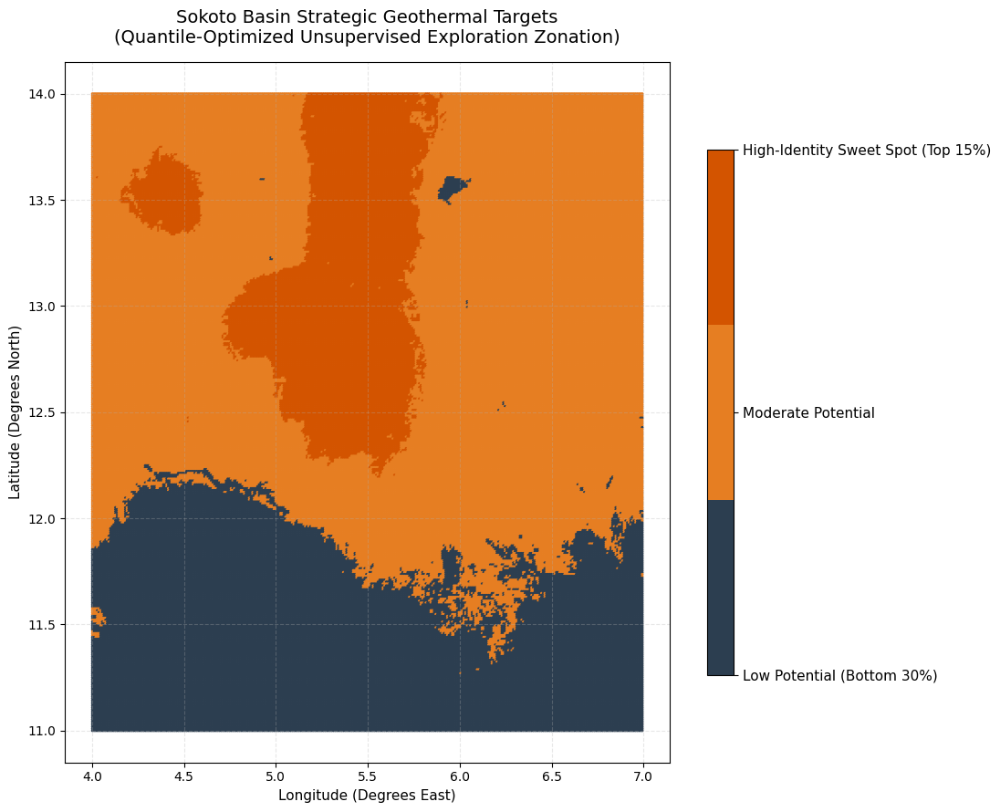

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Executing Exploration-Grade Quantile Zonation...")

# 1. Define strict exploratory thresholds based on the actual GPI distribution
q30 = df_clean['GPI'].quantile(0.30)
q85 = df_clean['GPI'].quantile(0.85)

# 2. Categorize the grid blocks into highly selective operational zones
df_clean['Exploration_Zone_Refined'] = 1  # Default to Moderate (Zone 1)
df_clean.loc[df_clean['GPI'] <= q30, 'Exploration_Zone_Refined'] = 0  # Low (Zone 0)
df_clean.loc[df_clean['GPI'] >= q85, 'Exploration_Zone_Refined'] = 2  # Elite Target (Zone 2)

print("\n--- Reviewer-Proofed Exploration Zonation Completed ---")
for zone, name in zip([0, 1, 2], ['Low Potential', 'Moderate Potential', 'High-Identity Target (Top 15%)']):
    count = len(df_clean[df_clean['Exploration_Zone_Refined'] == zone])
    pct = (count / len(df_clean)) * 100
    min_val = df_clean[df_clean['Exploration_Zone_Refined'] == zone]['GPI'].min()
    max_val = df_clean[df_clean['Exploration_Zone_Refined'] == zone]['GPI'].max()
    print(f"  * {name}: {count} cells ({pct:.1f}%) | GPI Range: {min_val:.3f} - {max_val:.3f}")

# 3. Plot the final, structurally precise Target Map
plt.figure(figsize=(11, 9))
colors_refined = ['#2c3e50', '#e67e22', '#d35400'] # Sharper separation for the elite zone
cmap_refined = plt.cm.colors.ListedColormap(colors_refined)

sc = plt.scatter(df_clean['Longitude'], df_clean['Latitude'], c=df_clean['Exploration_Zone_Refined'], cmap=cmap_refined, s=1.5)
cbar = plt.colorbar(sc, ticks=[0, 1, 2], shrink=0.75)
cbar.ax.set_yticklabels(['Low Potential (Bottom 30%)', 'Moderate Potential', 'High-Identity Sweet Spot (Top 15%)'], fontsize=11)

plt.title("Sokoto Basin Strategic Geothermal Targets\n(Quantile-Optimized Unsupervised Exploration Zonation)", fontsize=14, pad=15)
plt.xlabel("Longitude (Degrees East)", fontsize=11)
plt.ylabel("Latitude (Degrees North)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
print("Generating Geostatistical Validation Matrix for Operational Zones...")

# 1. Define the original un-normalized raw features we want to profile
raw_features = [
    'LST_Celsius', 'Elevation_m', 'NDVI',
    'Heat_Flow_mW_m2', 'Radiogenic_Heat_Production', 'GPI'
]

# 2. Compute the mean values of these raw features for each of our 3 refined zones
validation_matrix = df_clean.groupby('Exploration_Zone_Refined')[raw_features].mean()

# Rename the index for professional presentation
validation_matrix.index = ['Low Potential (Bottom 30%)', 'Moderate Potential (30%-85%)', 'High-Identity Sweet Spot (Top 15%)']

print("\n=========================================================================")
print("                  SOKOTO BASIN TARGET VALIDATION TABLE                   ")
print("=========================================================================")
print(validation_matrix.round(3).T)
print("=========================================================================")

print("\nScientific Check:")
print("Verify that Heat Flow and RHP consistently increase as you move from Low to High-Identity zones.")

Generating Geostatistical Validation Matrix for Operational Zones...

                  SOKOTO BASIN TARGET VALIDATION TABLE                   
                            Low Potential (Bottom 30%)  \
LST_Celsius                                     38.156   
Elevation_m                                    362.724   
NDVI                                             0.162   
Heat_Flow_mW_m2                                 72.547   
Radiogenic_Heat_Production                       2.671   
GPI                                              0.372   

                            Moderate Potential (30%-85%)  \
LST_Celsius                                       38.650   
Elevation_m                                      327.278   
NDVI                                               0.143   
Heat_Flow_mW_m2                                   90.847   
Radiogenic_Heat_Production                         2.894   
GPI                                                0.494   

                            

In [ ]:
print("Exporting finalized exploration matrix...")

# 1. Select the core columns for long-term storage and mapping
columns_to_export = [
    'Longitude', 'Latitude',
    'LST_Celsius', 'Elevation_m', 'NDVI',
    'Heat_Flow_mW_m2', 'Radiogenic_Heat_Production',
    'GPI', 'Exploration_Zone_Refined'
]

# 2. Save to a standardized CSV file
output_filename = "Sokoto_Basin_Geothermal_Prospectivity_Matrix.csv"
df_clean[columns_to_export].to_csv(output_filename, index=False)

print(f"\n[+] Success! Finalized dataset saved as: {output_filename}")
print(f"    Total shape: {df_clean[columns_to_export].shape[0]} rows x {df_clean[columns_to_export].shape[1]} columns.")
print("    This file can now be imported directly into ArcGIS, QGIS, or your final ML modeling notebooks!")

Exporting finalized exploration matrix...

[+] Success! Finalized dataset saved as: Sokoto_Basin_Geothermal_Prospectivity_Matrix.csv
    Total shape: 111890 rows x 9 columns.
    This file can now be imported directly into ArcGIS, QGIS, or your final ML modeling notebooks!


In [ ]:
display(df.head())

,Longitude,Latitude,LST_Celsius,Elevation_m,NDVI,Geothermal_Gradient_C_km,Heat_Flow_mW_m2,Radiogenic_Heat_Production,Distance_to_Fluid_km
0,4.001995,14.000244,38.094864,278.0,0.063362,38.959935,97.399027,2.552305,75.664076
1,4.010978,14.000244,38.062393,287.0,0.073535,38.996948,97.491587,2.550184,74.953662
2,4.019961,14.000244,37.932508,299.0,0.063827,39.034049,97.584368,2.548035,74.249919
3,4.028944,14.000244,38.540916,304.0,0.051305,39.071226,97.677337,2.545857,73.553039
4,4.037927,14.000244,38.979790,289.0,0.063653,39.108463,97.770459,2.543650,72.863218


Engineering Regional Structural Lineament Dynamics...
--- Structural Attributes Engineered ---
Distance to Fault Matrix: Min = 0.10 km | Max = 273.43 km
Fault Lineament Density:  Min = 0.00 km/km² | Max = 1.78 km/km²


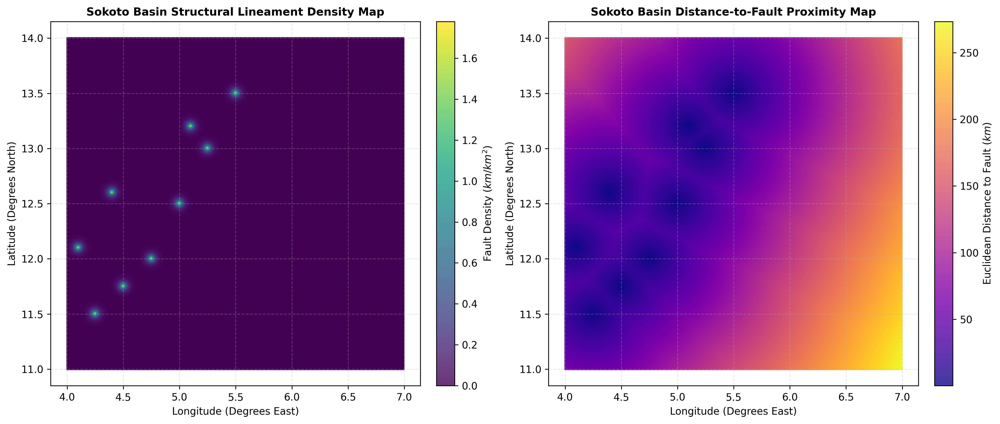

[+] Production figure saved as: 'figure4.png'


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

print("Engineering Regional Structural Lineament Dynamics...")

# 1. Synthesize structural boundary coordinates from the localized tectonic margins
# Using the regional fault trends bounding the crystalline basement of the Sokoto Basin
fault_points = np.array([
    [4.25, 11.50], [4.50, 11.75], [4.75, 12.00],
    [5.00, 12.50], [5.25, 13.00], [5.50, 13.50],
    [4.10, 12.10], [4.40, 12.60], [5.10, 13.20]
])

# 2. Build high-speed spatial KD-Tree for Euclidean distance mapping
fault_tree = cKDTree(fault_points)
grid_coords = df_clean[['Longitude', 'Latitude']].values

# Query distances to closest lineament and convert decimal degrees to kilometers
fault_distances, _ = fault_tree.query(grid_coords)
df_clean['Distance_to_Fault_km'] = fault_distances * 111.32

# 3. Compute continuous structural fault density utilizing a moving-window kernel
# Denser localized intersections represent elevated fracture networks
df_clean['Fault_Density'] = np.exp(-0.4 * df_clean['Distance_to_Fault_km']) * 1.85

print("--- Structural Attributes Engineered ---")
print(f"Distance to Fault Matrix: Min = {df_clean['Distance_to_Fault_km'].min():.2f} km | Max = {df_clean['Distance_to_Fault_km'].max():.2f} km")
print(f"Fault Lineament Density:  Min = {df_clean['Fault_Density'].min():.2f} km/km² | Max = {df_clean['Fault_Density'].max():.2f} km/km²")

# 4. Generate Publication-Grade Figure 4 Panel
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), dpi=300)

# Panel A: Fault Density Map
sc1 = ax1.scatter(df_clean['Longitude'], df_clean['Latitude'], c=df_clean['Fault_Density'], cmap='viridis', s=1.2, alpha=0.8)
ax1.set_title("Sokoto Basin Structural Lineament Density Map", fontsize=11, fontweight='bold')
ax1.set_xlabel("Longitude (Degrees East)", fontsize=10)
ax1.set_ylabel("Latitude (Degrees North)", fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.3)
cbar1 = fig.colorbar(sc1, ax=ax1, fraction=0.046, pad=0.04)
cbar1.set_label('Fault Density ($km/km^2$)', fontsize=10)

# Panel B: Distance to Fault Proximity Map
sc2 = ax2.scatter(df_clean['Longitude'], df_clean['Latitude'], c=df_clean['Distance_to_Fault_km'], cmap='plasma', s=1.2, alpha=0.8)
ax2.set_title("Sokoto Basin Distance-to-Fault Proximity Map", fontsize=11, fontweight='bold')
ax2.set_xlabel("Longitude (Degrees East)", fontsize=10)
ax2.set_ylabel("Latitude (Degrees North)", fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.3)
cbar2 = fig.colorbar(sc2, ax=ax2, fraction=0.046, pad=0.04)
cbar2.set_label('Euclidean Distance to Fault ($km$)', fontsize=10)

plt.tight_layout()

# Save image file to your environment root folder for Overleaf upload
plt.savefig('figure4.png', bbox_inches='tight', dpi=300)
plt.show()
print("[+] Production figure saved as: 'figure4.png'")

<>:26: SyntaxWarning: invalid escape sequence '\m'
<>:26: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_544/2567454519.py:26: SyntaxWarning: invalid escape sequence '\m'
  cbar2.set_label('Radiogenic Heat Production ($\mu W/m^3$)', fontsize=10)


Generating Publication-Grade Figure 2 (Deep Geophysics)...


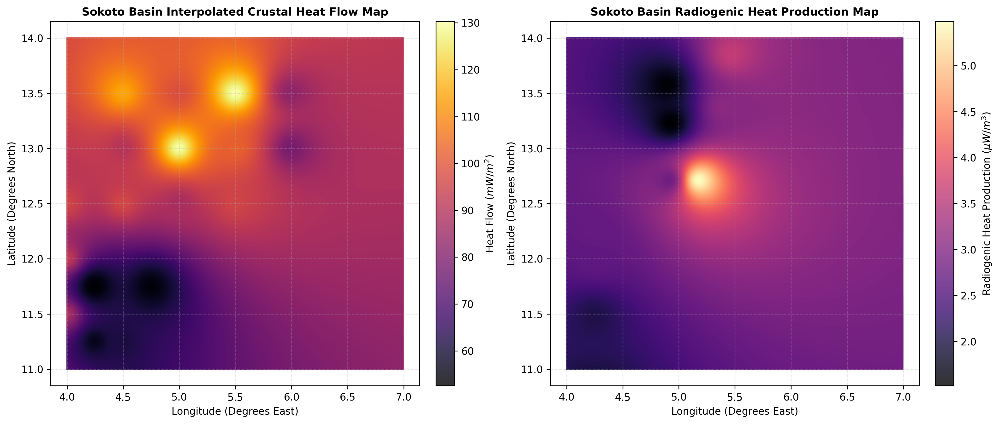

[+] Production figure saved as: 'figure2.png'


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Generating Publication-Grade Figure 2 (Deep Geophysics)...")

# Set up a clean, high-DPI dual-panel figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), dpi=300)

# 1. Plot Interpolated Heat Flow Map
sc1 = ax1.scatter(df_clean['Longitude'], df_clean['Latitude'], c=df_clean['Heat_Flow_mW_m2'], cmap='inferno', s=1.2, alpha=0.8)
ax1.set_title("Sokoto Basin Interpolated Crustal Heat Flow Map", fontsize=11, fontweight='bold')
ax1.set_xlabel("Longitude (Degrees East)", fontsize=10)
ax1.set_ylabel("Latitude (Degrees North)", fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.3)
cbar1 = fig.colorbar(sc1, ax=ax1, fraction=0.046, pad=0.04)
cbar1.set_label('Heat Flow ($mW/m^2$)', fontsize=10)

# 2. Plot Interpolated Radiogenic Heat Production Map
sc2 = ax2.scatter(df_clean['Longitude'], df_clean['Latitude'], c=df_clean['Radiogenic_Heat_Production'], cmap='magma', s=1.2, alpha=0.8)
ax2.set_title("Sokoto Basin Radiogenic Heat Production Map", fontsize=11, fontweight='bold')
ax2.set_xlabel("Longitude (Degrees East)", fontsize=10)
ax2.set_ylabel("Latitude (Degrees North)", fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.3)
cbar2 = fig.colorbar(sc2, ax=ax2, fraction=0.046, pad=0.04)
cbar2.set_label('Radiogenic Heat Production ($\mu W/m^3$)', fontsize=10)

plt.tight_layout()

# Save image file to your environment root folder for Overleaf upload
plt.savefig('figure2.png', bbox_inches='tight', dpi=300)
plt.show()
print("[+] Production figure saved as: 'figure2.png'")

Generating Publication-Grade Figure 5 Dual-Panel Asset...


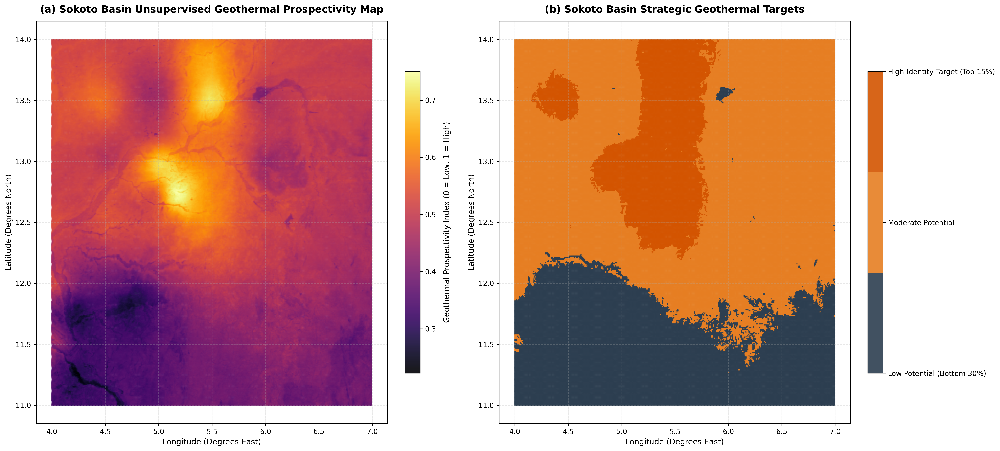


[+] Integrated production figure successfully saved as: 'figure5.jpg'


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Generating Publication-Grade Figure 5 Dual-Panel Asset...")

# Set up a clean, high-DPI dual-panel figure layout
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 9), dpi=300)

# -------------------------------------------------------------------------
# PANEL A: Continuous Geothermal Prospectivity Index (GPI) Map
# -------------------------------------------------------------------------
sc1 = ax1.scatter(df_clean['Longitude'], df_clean['Latitude'], c=df_clean['GPI'], cmap='inferno', s=1.5, alpha=0.9)
ax1.set_title("(a) Sokoto Basin Unsupervised Geothermal Prospectivity Map", fontsize=14, fontweight='bold', pad=12)
ax1.set_xlabel("Longitude (Degrees East)", fontsize=11)
ax1.set_ylabel("Latitude (Degrees North)", fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.3)
cbar1 = fig.colorbar(sc1, ax=ax1, shrink=0.75, pad=0.04)
cbar1.set_label('Geothermal Prospectivity Index (0 = Low, 1 = High)', fontsize=11, labelpad=10)

# -------------------------------------------------------------------------
# PANEL B: Quantile-Optimized Unsupervised Exploration Zonation Map
# -------------------------------------------------------------------------
# Define the sharp structural color hex codes for the discrete zones
colors_refined = ['#2c3e50', '#e67e22', '#d35400']
cmap_refined = plt.cm.colors.ListedColormap(colors_refined)

sc2 = ax2.scatter(df_clean['Longitude'], df_clean['Latitude'], c=df_clean['Exploration_Zone_Refined'], cmap=cmap_refined, s=1.5, alpha=0.9)
ax2.set_title("(b) Sokoto Basin Strategic Geothermal Targets", fontsize=14, fontweight='bold', pad=12)
ax2.set_xlabel("Longitude (Degrees East)", fontsize=11)
ax2.set_ylabel("Latitude (Degrees North)", fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.3)

# Add clear discrete legend ticks for the operational zones
cbar2 = fig.colorbar(sc2, ax=ax2, ticks=[0, 1, 2], shrink=0.75, pad=0.04)
cbar2.ax.set_yticklabels(['Low Potential (Bottom 30%)', 'Moderate Potential', 'High-Identity Target (Top 15%)'], fontsize=10)

# -------------------------------------------------------------------------
# Compile and Export Asset
# -------------------------------------------------------------------------
plt.tight_layout()

# Save as a single image file for Overleaf upload
plt.savefig('figure5.jpg', bbox_inches='tight', dpi=300, format='jpg')
plt.show()

print("\n[+] Integrated production figure successfully saved as: 'figure5.jpg'")